# Week 9 · Topic 1 — Why Hash, Not Encrypt

**Mohammed Mohammed Alhaji** · CST1510 · 26 November 2026

**Box we are building: PROCESS, made safe**

Before any bcrypt function, the concept: what hashing actually is, and why it
is the right tool for a password.

> **Already know this?** Skip to the *Topic 1 Challenge*, then help a neighbour.

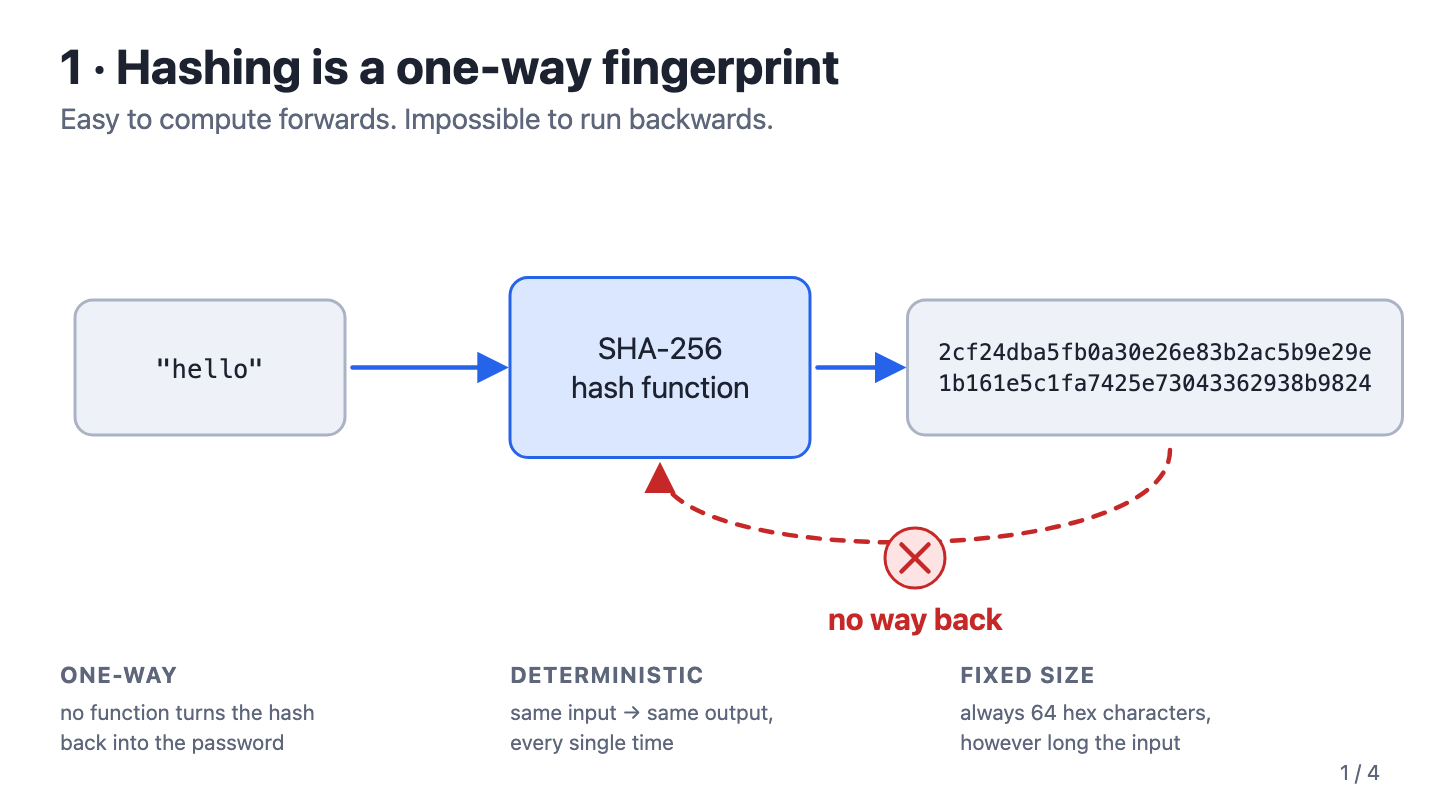

---
## 1. Hashing is one-way, deterministic, and a fixed size

Same input, same output, always — and no function reverses it back.

These SHA-256 examples explain hashing using public practice values. For stored
passwords, use a password-hashing function such as bcrypt with a fresh salt.


In [1]:
import hashlib

print(hashlib.sha256(b"password123").hexdigest())
print(hashlib.sha256(b"password123").hexdigest())   # identical, every time

ef92b778bafe771e89245b89ecbc08a44a4e166c06659911881f383d4473e94f
ef92b778bafe771e89245b89ecbc08a44a4e166c06659911881f383d4473e94f


### Your turn
Hash your own name with `hashlib.sha256` and confirm hashing it twice gives the same result.

In [2]:
name = "Mohammed Mohammed Alhaji"
first_hash = hashlib.sha256(name.encode("utf-8")).hexdigest()
second_hash = hashlib.sha256(name.encode("utf-8")).hexdigest()
print(first_hash)
print(second_hash)
print("Same name, same hash:", first_hash == second_hash)
assert first_hash == second_hash


b6044590c1e2b71d7eb0a8abf2d19b21417eeef07f1d9a515e2cfc72227c53fa
b6044590c1e2b71d7eb0a8abf2d19b21417eeef07f1d9a515e2cfc72227c53fa
Same name, same hash: True


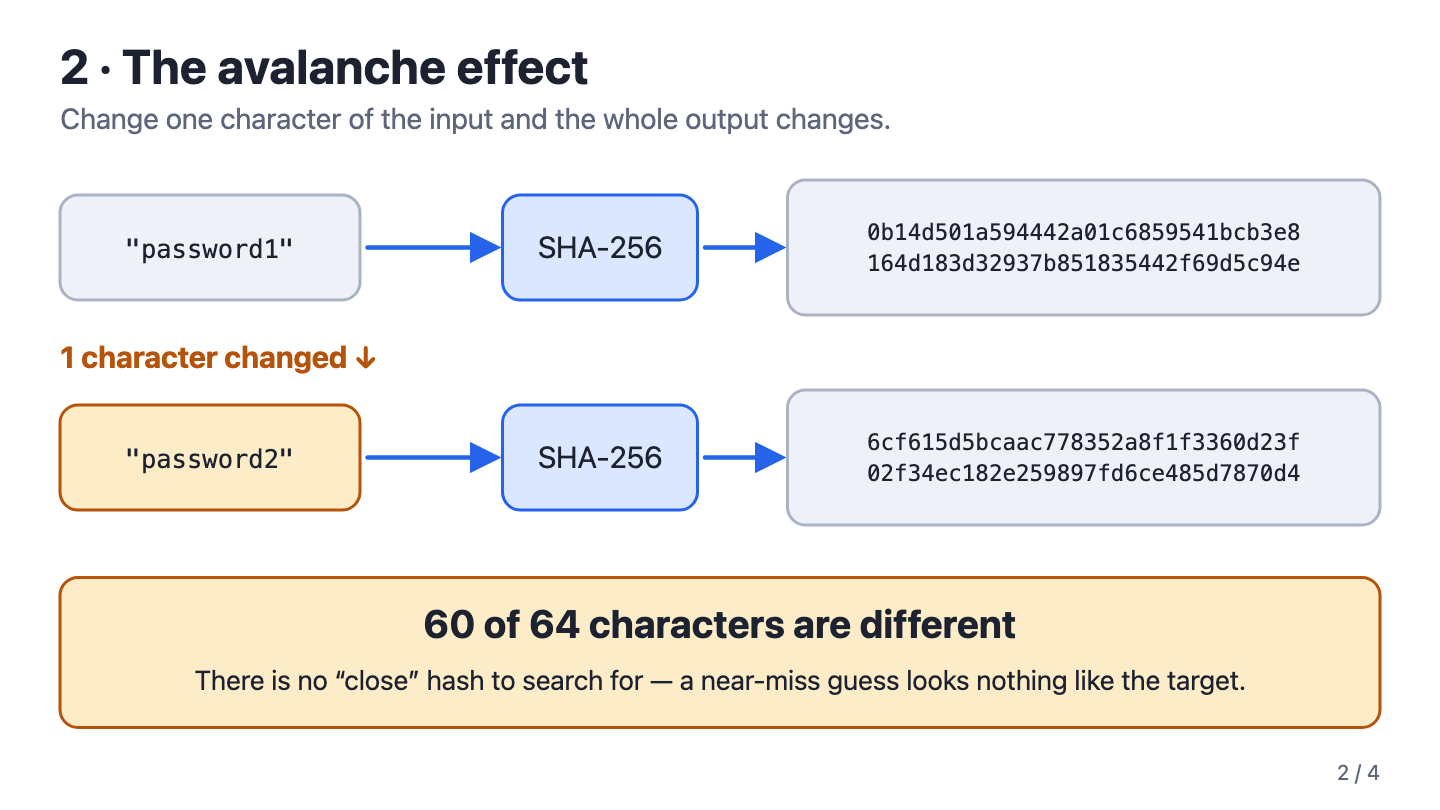

---
## 2. The avalanche effect

One character different in the input changes the entire output — there is no
"close" match to look for.

In [3]:
print(hashlib.sha256(b"password123").hexdigest())
print(hashlib.sha256(b"password124").hexdigest())

ef92b778bafe771e89245b89ecbc08a44a4e166c06659911881f383d4473e94f
33631376724e5d5480fa397dfcf03b66ad47b934ab495174d7058c38f2bb0087


### Your turn
Change one character in a string of your own and compare the two hashes.

In [4]:
original = "dataset rows: 229"
changed = "dataset rows: 228"  # Only the final character changes.
original_hash = hashlib.sha256(original.encode("utf-8")).hexdigest()
changed_hash = hashlib.sha256(changed.encode("utf-8")).hexdigest()
print("Original:", original_hash)
print("Changed: ", changed_hash)
print("Data changed:", original_hash != changed_hash)
print("Both digests have", len(original_hash), "hexadecimal characters.")
# This is also the idea behind a data integrity check: compare with a trusted digest.
assert original_hash != changed_hash
assert len(original_hash) == len(changed_hash) == 64


Original: 3c5ee02766944af5d1b6415c35ce56833c1bb60cf74af80beb3983d88136f75b
Changed:  261256d77480acbe4b98e18f3689f062e9eff0ff1f7b1259ec6cf603b8d3236d
Data changed: True
Both digests have 64 hexadecimal characters.


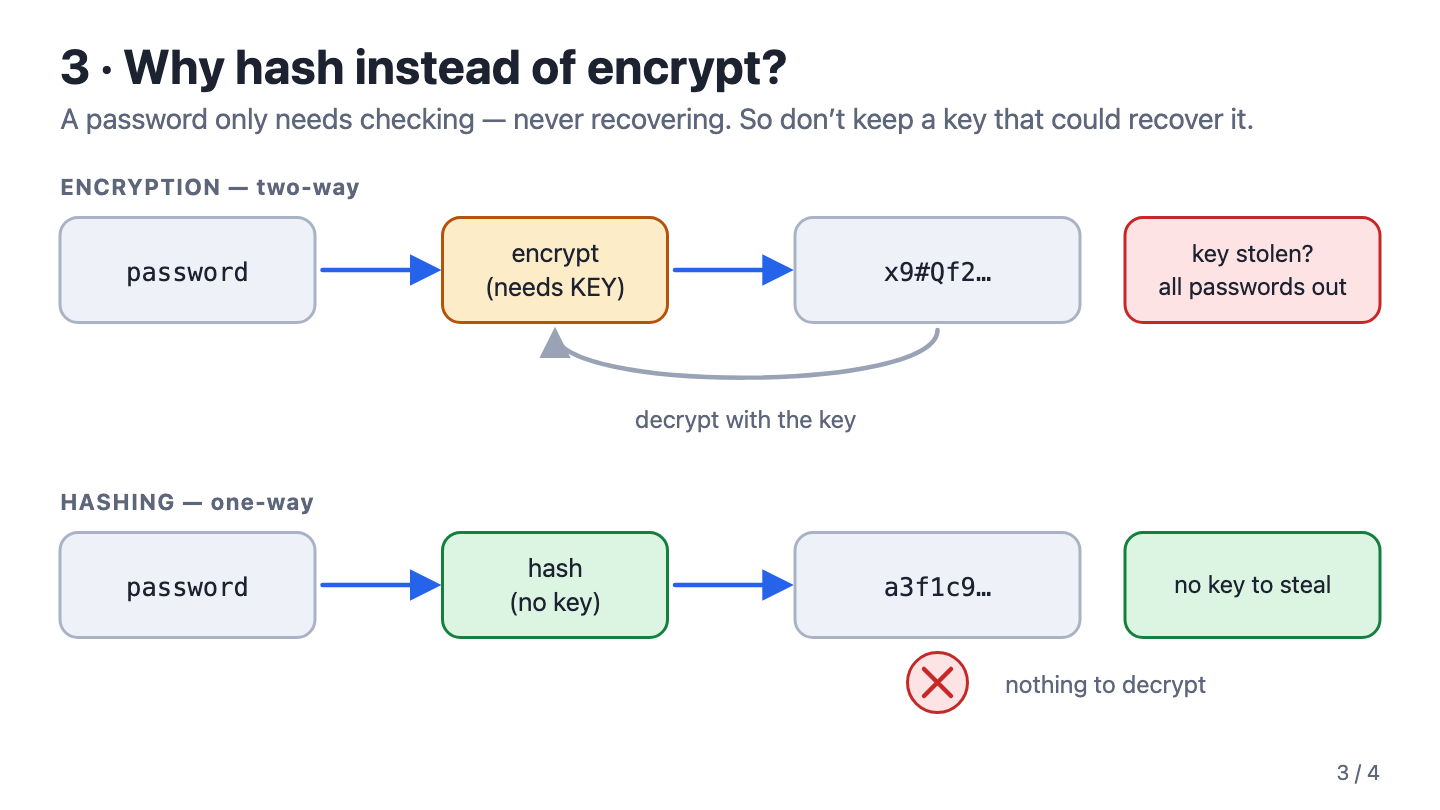

---
## 3. Why not encryption?

Encryption is two-way — whoever holds the key can decrypt it back. A password
only ever needs *checking*, never recovering, so a one-way hash is the safer
tool: there is no key to steal.

In [5]:
typed = "password123"
stored_hash = hashlib.sha256(b"password123").hexdigest()

# verify by hashing AGAIN and comparing - never by decrypting
print(hashlib.sha256(typed.encode()).hexdigest() == stored_hash)

True


### Your turn
Explain, in your own words, why "hash again and compare" replaces "decrypt and compare" for a password.

In [6]:
print(
    "A login only needs to check whether the entered password is correct. "
    "It does not need to recover the original password. "
    "The password-hashing function checks the entered value against the stored hash; "
    "with bcrypt, checkpw uses the salt and cost stored in that hash. "
    "There is no decryption key to store or steal."
)


A login only needs to check whether the entered password is correct. It does not need to recover the original password. The password-hashing function checks the entered value against the stored hash; with bcrypt, checkpw uses the salt and cost stored in that hash. There is no decryption key to store or steal.


### Salting: a defensive comparison

| Practice situation | Result |
|---|---|
| Same password, same hash settings and salt | Same result |
| Same password, fresh random salt for each account | Different stored hashes |
| Correct password checked with each stored bcrypt hash | Both verifications succeed |

This defensive comparison replaces the supplied hash-lookup diagram. The code below
checks salt separation and normal password verification using dummy values.


---
## 4. Rainbow tables, and why salting prevents reuse

Precomputed password-hash tables rely on reusing work across unsalted hashes.
A fresh random salt for each stored password changes the calculation, so a table
prepared without that salt cannot be reused directly across accounts.

A salt is not a secret and does not make a weak password strong. bcrypt stores the
salt in its output and makes each password check deliberately expensive.

**Defensive substitution:** the supplied table-lookup code is replaced with a
same-password, distinct-salts demonstration. No password recovery is performed.


In [7]:
import bcrypt

practice_password = b"classroom-demo-password"
salt_a = bcrypt.gensalt()
salt_b = bcrypt.gensalt()
hash_a = bcrypt.hashpw(practice_password, salt_a)
hash_b = bcrypt.hashpw(practice_password, salt_b)

print("Distinct salts:", salt_a != salt_b)
print("Distinct stored hashes:", hash_a != hash_b)
print("Account A verifies:", bcrypt.checkpw(practice_password, hash_a))
print("Account B verifies:", bcrypt.checkpw(practice_password, hash_b))
assert salt_a != salt_b
assert hash_a != hash_b
assert bcrypt.checkpw(practice_password, hash_a)
assert bcrypt.checkpw(practice_password, hash_b)


Distinct salts: True
Distinct stored hashes: True
Account A verifies: True


Account B verifies: True


### Your turn
**Defensive substitution for the supplied hash-lookup exercise:** hash the same
practice password for a third account using a fresh salt. Check that its salt and
hash differ from the first two accounts, and verify the password normally.
Explain what this shows about reusing precomputed hashes across accounts.


In [8]:
salt_c = bcrypt.gensalt()
hash_c = bcrypt.hashpw(practice_password, salt_c)
print("Third salt is distinct:", salt_c != salt_a and salt_c != salt_b)
print("Third hash is distinct:", hash_c != hash_a and hash_c != hash_b)
print("Third account verifies:", bcrypt.checkpw(practice_password, hash_c))
print("Each salt changes the result, so one unsalted precomputed result cannot serve all accounts.")
assert salt_c != salt_a and salt_c != salt_b
assert hash_c != hash_a and hash_c != hash_b
assert bcrypt.checkpw(practice_password, hash_c)


Third salt is distinct: True
Third hash is distinct: True
Third account verifies: True
Each salt changes the result, so one unsalted precomputed result cannot serve all accounts.


---
## Topic 1 Challenge

**Defensive substitution for the supplied password-table challenge:** generate a
long random practice password, hash it twice with fresh bcrypt salts, and verify
it against both stored hashes. Confirm that the stored hashes differ. Explain in
one sentence why length and randomness matter more than a particular character rule.


In [9]:
import secrets

random_password = secrets.token_urlsafe(24)
random_bytes = random_password.encode("utf-8")
first_stored = bcrypt.hashpw(random_bytes, bcrypt.gensalt())
second_stored = bcrypt.hashpw(random_bytes, bcrypt.gensalt())
print("Practice password length:", len(random_password))
print("Distinct stored hashes:", first_stored != second_stored)
print("First verification:", bcrypt.checkpw(random_bytes, first_stored))
print("Second verification:", bcrypt.checkpw(random_bytes, second_stored))
print("Length and genuine randomness make a password less predictable than following a fixed character rule.")
assert first_stored != second_stored
assert bcrypt.checkpw(random_bytes, first_stored)
assert bcrypt.checkpw(random_bytes, second_stored)


Practice password length: 32
Distinct stored hashes: True
First verification: True


Second verification: True
Length and genuine randomness make a password less predictable than following a fixed character rule.


---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | hashing to check whether two data files are identical, without comparing every byte |
| **Cyber Security** | recognising a rainbow-table attack against a leaked password database |
| **IT** | verifying a downloaded file has not been tampered with, via its published hash |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| calling hashing "encryption" | technically wrong, and the wrong mental model | hashing has no key and cannot be reversed — encryption does and can |
| assuming a hash can be "decoded" back to the password | there is no function for this | verification checks the entered password against the stored hash |
| using an unsalted hash for passwords | vulnerable to a pre-computed rainbow table | always salt — bcrypt does this for you automatically (Topic 2) |
| picking a "clever" but common password | it is very likely already in an attacker's table | length and genuine randomness beat cleverness |

## Go deeper

`examples/01_what_hashing_actually_does.py` — determinism, the avalanche effect, one-way
Docs: [Python hashlib](https://docs.python.org/3/library/hashlib.html)

---
## Recap

| You can now | Using |
|---|---|
| explain what a hash is | one-way, deterministic, fixed size |
| explain why not encryption | no key to steal, never needs reversing |
| explain a rainbow table attack | pre-computed hashes of common passwords |
| explain why salting defeats it | a unique salt makes every hash different |

**Next:** Topic 2 — doing this properly, with bcrypt.